# Lumos Ultra — Z-axis metrology

Select **factory** or **rebuilt**, then **Run All**. Missing datasets are skipped; the rebuilt general benchmark can be added later.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN = "rebuilt"  # change to "rebuilt" for the post-modification run
RUNS = {
    "factory": (
        "logs/zbench_20260925_172313",
        "logs/layer_spacing_20260925_190700",
    ),
    "rebuilt": (
        "logs/zbench_20261101_114458",
        "logs/layer_spacing_20261101_132445",
    ),
}

LABEL = RUN.title()
bench_dir, layers_dir = RUNS[RUN]
bench_file = Path(bench_dir) / "points.csv" if bench_dir else None
layers_file = Path(layers_dir) / "layers.csv" if layers_dir else None

if not ((bench_file and bench_file.is_file()) or
        (layers_file and layers_file.is_file())):
    raise FileNotFoundError(f"No data found for {RUN}. Check the paths in RUNS.")

points = pd.read_csv(bench_file) if bench_file and bench_file.is_file() else None
layers = pd.read_csv(layers_file) if layers_file and layers_file.is_file() else None

if points is not None:
    points["requested_offset_mm"] = pd.to_numeric(points["requested_offset_mm"], errors="coerce")
    points["encoder_relative_um"] = pd.to_numeric(points["encoder_relative_um"], errors="coerce")
    moving = points.loc[
        points["test"].isin(["dense_20um", "long_500um"])
        & points["requested_offset_mm"].abs().gt(0.05)
    ]
    correlation = moving["requested_offset_mm"].corr(moving["encoder_relative_um"])
    if not np.isfinite(correlation):
        raise ValueError("Cannot determine Parker encoder direction from benchmark points.")
    sign = 1 if correlation > 0 else -1
    points["z_mm"] = points["requested_offset_mm"]
    points["measured_um"] = sign * points["encoder_relative_um"]
    points["commanded_um"] = 1000 * points["z_mm"]
    points["error_um"] = points["measured_um"] - points["commanded_um"]

if layers is not None:
    for name in ("pass", "commanded_from_pass_start_um", "commanded_spacing_um",
                 "physical_spacing_um", "step_error_um", "cumulative_position_error_um"):
        layers[name] = pd.to_numeric(layers[name], errors="coerce")

## Position error

Measured minus commanded Z. Forward/reverse separation indicates hysteresis.

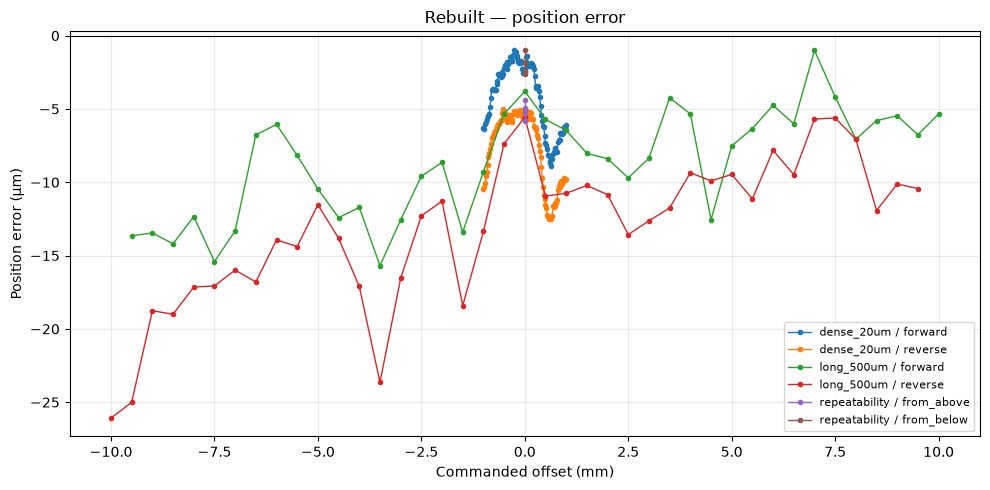

In [2]:
if points is not None:
    fig, ax = plt.subplots(figsize=(10, 5))
    data = points[points["test"].isin(["dense_20um", "long_500um", "repeatability"])]
    for (test, direction), g in data.groupby(["test", "direction"]):
        if len(g) > 1:
            ax.plot(g["z_mm"], g["error_um"], ".-", lw=1, label=f"{test} / {direction}")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel="Commanded offset (mm)", ylabel="Position error (µm)",
           title=f"{LABEL} — position error")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()

## Local error

Linear offset and scale are removed **separately for each direction** to reveal nonlinear error.

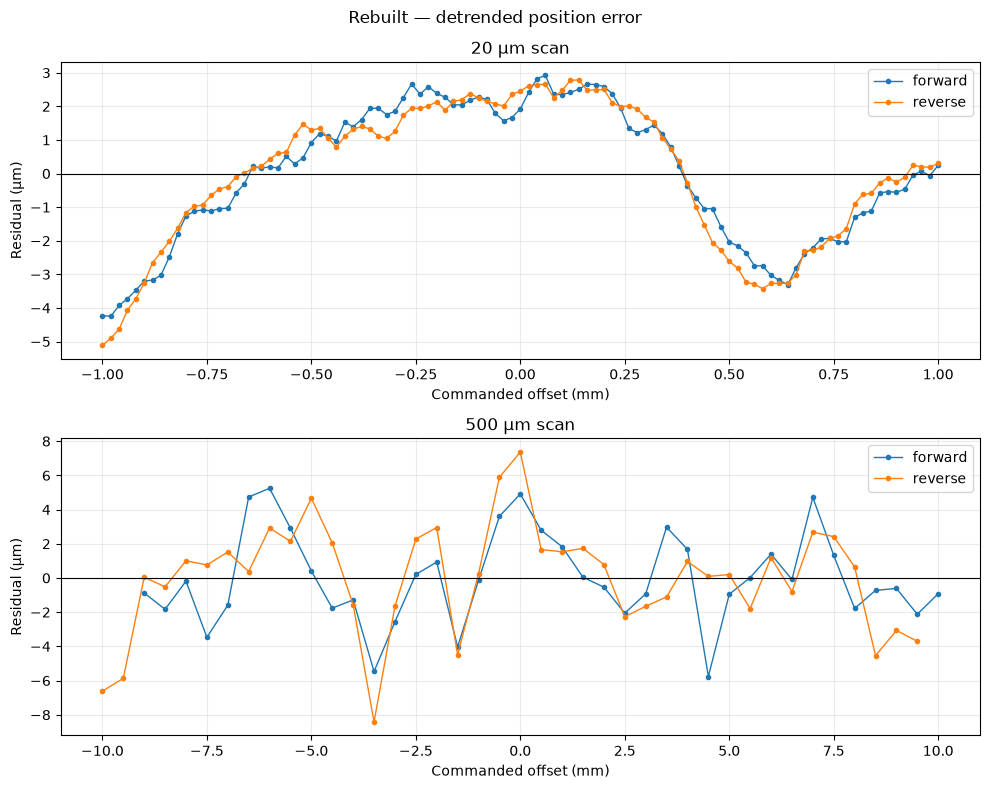

In [3]:
if points is not None:
    scans = [("dense_20um", "20 µm scan"), ("long_500um", "500 µm scan")]
    fig, axes = plt.subplots(2, 1, figsize=(10, 8))
    for ax, (test, heading) in zip(axes, scans):
        for direction in ("forward", "reverse"):
            g = (points[(points["test"] == test) & (points["direction"] == direction)]
                 [["z_mm", "measured_um"]].dropna().sort_values("z_mm"))
            # Original long-scan analysis excludes its first forward point.
            if test == "long_500um" and direction == "forward":
                g = g.iloc[1:]
            if len(g) < 3:
                continue
            x = 1000 * g["z_mm"].to_numpy()
            y = g["measured_um"].to_numpy()
            slope, offset = np.polyfit(x, y, 1)
            ax.plot(x / 1000, y - (slope * x + offset), ".-", lw=1, label=direction)
        ax.axhline(0, color="black", lw=0.8)
        ax.set(xlabel="Commanded offset (mm)", ylabel="Residual (µm)", title=heading)
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle(f"{LABEL} — detrended position error")
    fig.tight_layout()
    plt.show()

## Layer spacing

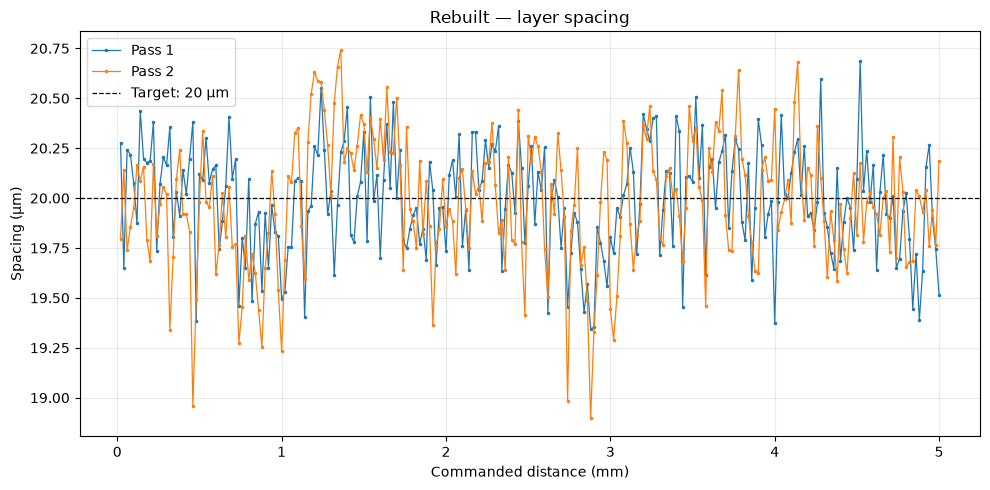

,mean,std,min,max,error RMS
pass,,,,,
1,19.991,0.270,19.345,20.685,0.270
2,19.978,0.317,18.898,20.743,0.317


In [4]:
if layers is not None:
    steps = layers.dropna(subset=["physical_spacing_um"])
    pitch = steps["commanded_spacing_um"].median()
    fig, ax = plt.subplots(figsize=(10, 5))
    for pass_id, g in steps.groupby("pass"):
        ax.plot(g["commanded_from_pass_start_um"] / 1000,
                g["physical_spacing_um"], ".-", ms=3, lw=0.9, label=f"Pass {int(pass_id)}")
    ax.axhline(pitch, color="black", ls="--", lw=0.9, label=f"Target: {pitch:g} µm")
    ax.set(xlabel="Commanded distance (mm)", ylabel="Spacing (µm)",
           title=f"{LABEL} — layer spacing")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()

    stats = steps.groupby("pass")["physical_spacing_um"].agg(["mean", "std", "min", "max"])
    stats["error RMS"] = steps.groupby("pass")["step_error_um"].apply(
        lambda s: np.sqrt(np.mean(s.dropna() ** 2)))
    display(stats.round(3))

## Cumulative error

Each pass starts at zero; this does not show absolute return-position repeatability.

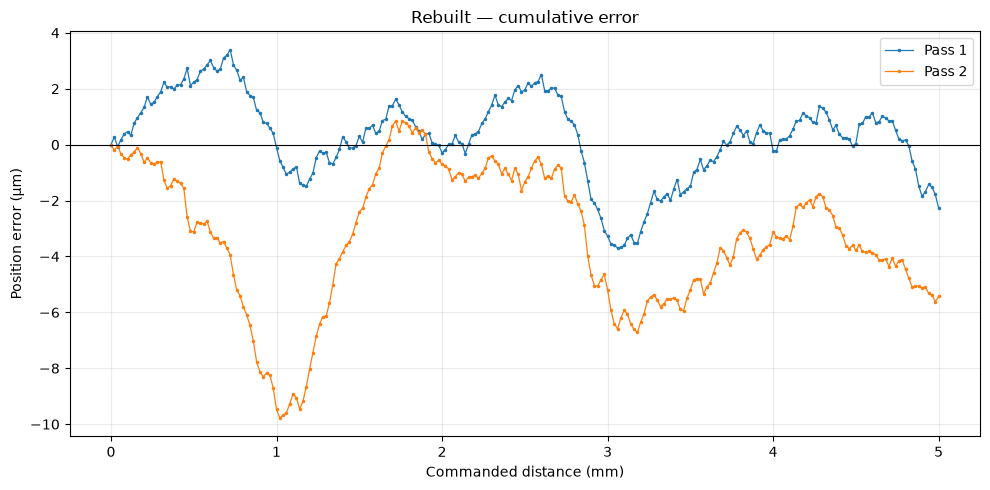

In [5]:
if layers is not None:
    fig, ax = plt.subplots(figsize=(10, 5))
    for pass_id, g in layers.groupby("pass"):
        ax.plot(g["commanded_from_pass_start_um"] / 1000,
                g["cumulative_position_error_um"], ".-", ms=3, lw=0.9,
                label=f"Pass {int(pass_id)}")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel="Commanded distance (mm)", ylabel="Position error (µm)",
           title=f"{LABEL} — cumulative error")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()